## Task 5: Analytics Report & Insights Documentation

### Step 1: Loading and exploring the dataset

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visualization style
sns.set_theme(style="whitegrid")

# Load dataset
df = pd.read_csv("Sample - Superstore.csv", encoding="latin1")

# Display basic information
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

Dataset Shape: (9994, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

First 5 Records:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


### Step 2: Checking data quality

In [2]:
# Dataset information
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Convert dates to datetime
df["Order Date"] = pd.to_datetime(
    df["Order Date"], format="%m/%d/%Y"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], format="%m/%d/%Y"
)

print("\nDate conversion completed!")

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000



Date conversion completed!


### Step 3: Calculating Key Performance Indicators (KPIs)

In [4]:
# Calculate business KPIs

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_quantity = df["Quantity"].sum()

profit_margin = (total_profit / total_sales) * 100
average_order_value = total_sales / total_orders

# Display KPI results
print("========== BUSINESS PERFORMANCE KPIs ==========")

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Average Order Value: ${average_order_value:,.2f}")

========== BUSINESS PERFORMANCE KPIs ==========
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Orders: 5,009
Total Customers: 793
Total Quantity Sold: 37,873
Profit Margin: 12.47%
Average Order Value: $458.61


### Step 4: Create a KPI Summary Table

In [5]:
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Profit",
        "Total Orders",
        "Total Customers",
        "Total Quantity Sold",
        "Profit Margin (%)",
        "Average Order Value"
    ],
    "Value": [
        round(total_sales, 2),
        round(total_profit, 2),
        total_orders,
        total_customers,
        total_quantity,
        round(profit_margin, 2),
        round(average_order_value, 2)
    ]
})

display(kpi_summary)

# Save results for documentation
kpi_summary.to_csv("Business_KPI_Summary.csv", index=False)

print("KPI summary saved successfully!")

,Metric,Value
0,Total Sales,2297200.86
1,Total Profit,286397.02
2,Total Orders,5009.00
3,Total Customers,793.00
4,Total Quantity Sold,37873.00
5,Profit Margin (%),12.47
6,Average Order Value,458.61


KPI summary saved successfully!


### Step 5: Sales and Profit Analysis

#### Step 5.1: Category-wise Sales and Profit

In [6]:
category_analysis = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Quantity_Sold=("Quantity", "sum")
).reset_index()

category_analysis["Profit_Margin"] = (
    category_analysis["Total_Profit"] /
    category_analysis["Total_Sales"] * 100
)

display(category_analysis.round(2))

,Category,Total_Sales,Total_Profit,Quantity_Sold,Profit_Margin
0,Furniture,741999.80,18451.27,8028,2.49
1,Office Supplies,719047.03,122490.80,22906,17.04
2,Technology,836154.03,145454.95,6939,17.40


#### Step 5.2: Region-wise Performance

In [7]:
region_analysis = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

region_analysis["Profit_Margin"] = (
    region_analysis["Total_Profit"] /
    region_analysis["Total_Sales"] * 100
)

display(region_analysis.round(2))

,Region,Total_Sales,Total_Profit,Total_Orders,Profit_Margin
0,Central,501239.89,39706.36,1175,7.92
1,East,678781.24,91522.78,1401,13.48
2,South,391721.90,46749.43,822,11.93
3,West,725457.82,108418.45,1611,14.94


#### Step 5.3: Customer Segment Analysis

In [8]:
segment_analysis = df.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Customers=("Customer ID", "nunique")
).reset_index()

segment_analysis["Profit_Margin"] = (
    segment_analysis["Total_Profit"] /
    segment_analysis["Total_Sales"] * 100
)

display(segment_analysis.round(2))

,Segment,Total_Sales,Total_Profit,Total_Customers,Profit_Margin
0,Consumer,1161401.34,134119.21,409,11.55
1,Corporate,706146.37,91979.13,236,13.03
2,Home Office,429653.15,60298.68,148,14.03


#### Step 5.4: Subcategory Profitability

In [9]:
subcategory_analysis = df.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Discount=("Discount", "mean")
).reset_index()

subcategory_analysis["Profit_Margin"] = (
    subcategory_analysis["Total_Profit"] /
    subcategory_analysis["Total_Sales"] * 100
)

subcategory_analysis = subcategory_analysis.sort_values(
    by="Total_Profit", ascending=False
)

display(subcategory_analysis.round(2))

,Sub-Category,Total_Sales,Total_Profit,Average_Discount,Profit_Margin
6,Copiers,149528.03,55617.82,0.16,37.20
13,Phones,330007.05,44515.73,0.15,13.49
0,Accessories,167380.32,41936.64,0.08,25.05
12,Paper,78479.21,34053.57,0.07,43.39
3,Binders,203412.73,30221.76,0.37,14.86
5,Chairs,328449.10,26590.17,0.17,8.10
14,Storage,223843.61,21278.83,0.07,9.51
1,Appliances,107532.16,18138.01,0.17,16.87
9,Furnishings,91705.16,13059.14,0.14,14.24
7,Envelopes,16476.40,6964.18,0.08,42.27


#### Step 5.5: Save the Analysis Results

In [10]:
category_analysis.to_csv("Category_Analysis.csv", index=False)
region_analysis.to_csv("Region_Analysis.csv", index=False)
segment_analysis.to_csv("Segment_Analysis.csv", index=False)
subcategory_analysis.to_csv("Subcategory_Analysis.csv", index=False)

print("All business analysis tables saved successfully!")

All business analysis tables saved successfully!


### Step 6: Create Meaningful Visualizations

#### Step 6.1: Set up the chart formatting

In [11]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

os.makedirs("Visualizations", exist_ok=True)

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

print("Visualization setup completed!")

Visualization setup completed!


#### Step 6.2: Sales and profit by category

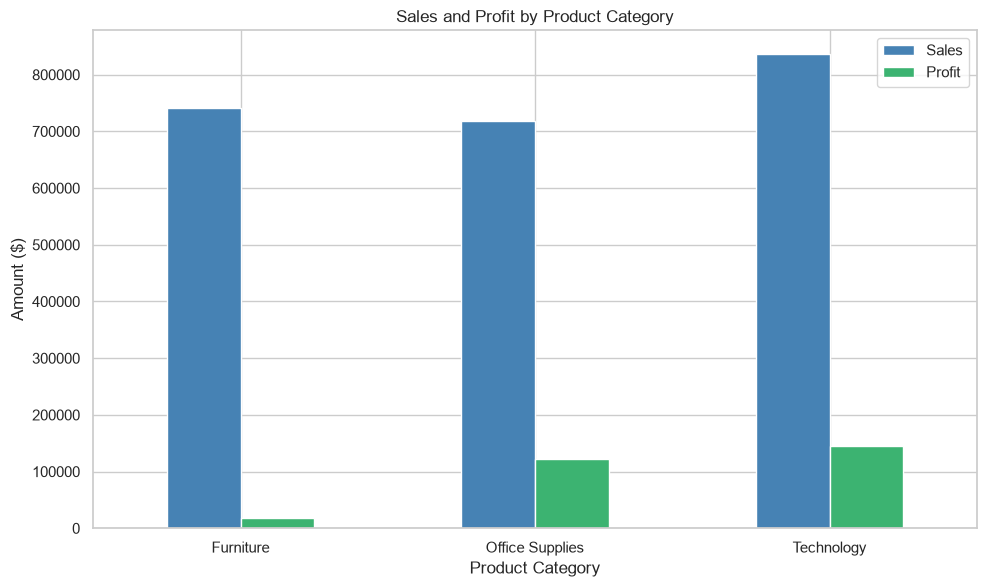

In [12]:
category_analysis.plot(
    x="Category",
    y=["Total_Sales", "Total_Profit"],
    kind="bar",
    figsize=(10, 6),
    color=["steelblue", "mediumseagreen"]
)

plt.title("Sales and Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.legend(["Sales", "Profit"])
plt.tight_layout()
plt.savefig("Visualizations/Category_Performance.png", dpi=300)
plt.show()

#### Step 6.3: Regional sales performance

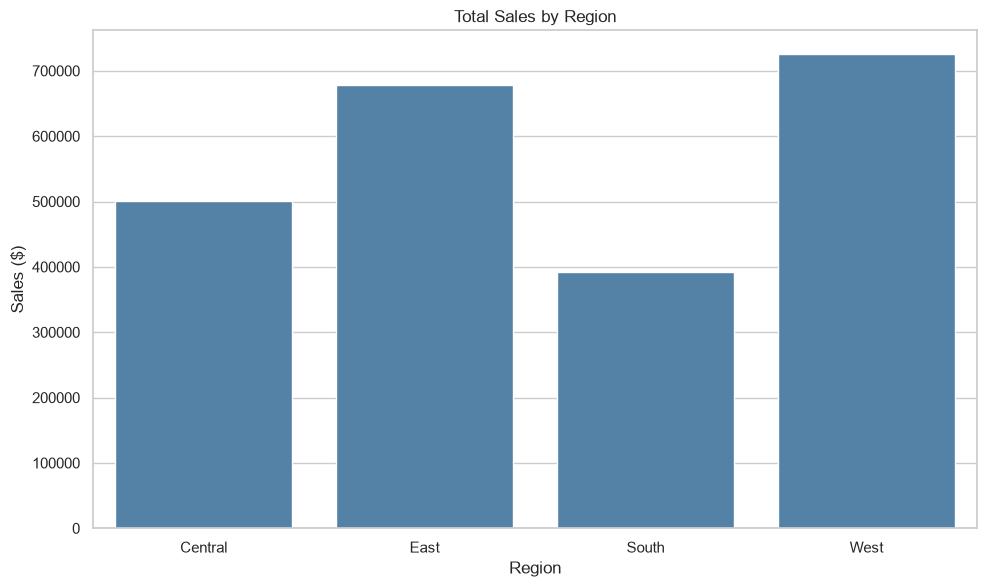

In [13]:
sns.barplot(
    data=region_analysis,
    x="Region",
    y="Total_Sales",
    color="steelblue"
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales ($)")
plt.tight_layout()
plt.savefig("Visualizations/Regional_Sales.png", dpi=300)
plt.show()

#### Step 6.4: Customer segment profitability

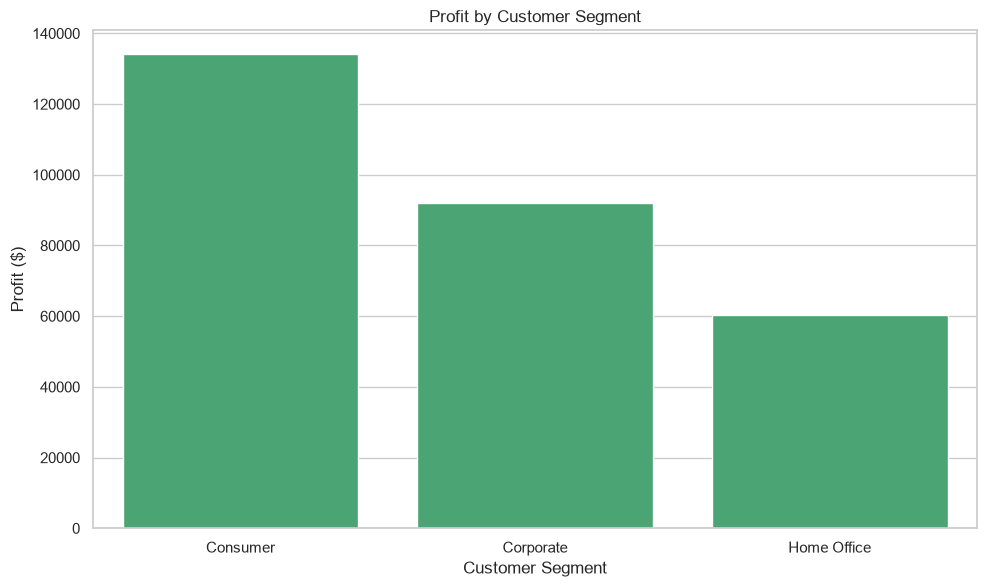

In [14]:
sns.barplot(
    data=segment_analysis,
    x="Segment",
    y="Total_Profit",
    color="mediumseagreen"
)

plt.title("Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Profit ($)")
plt.tight_layout()
plt.savefig("Visualizations/Segment_Profit.png", dpi=300)
plt.show()

#### Step 6.5: Monthly sales trend

Date column type: datetime64[us]
Invalid dates: 0


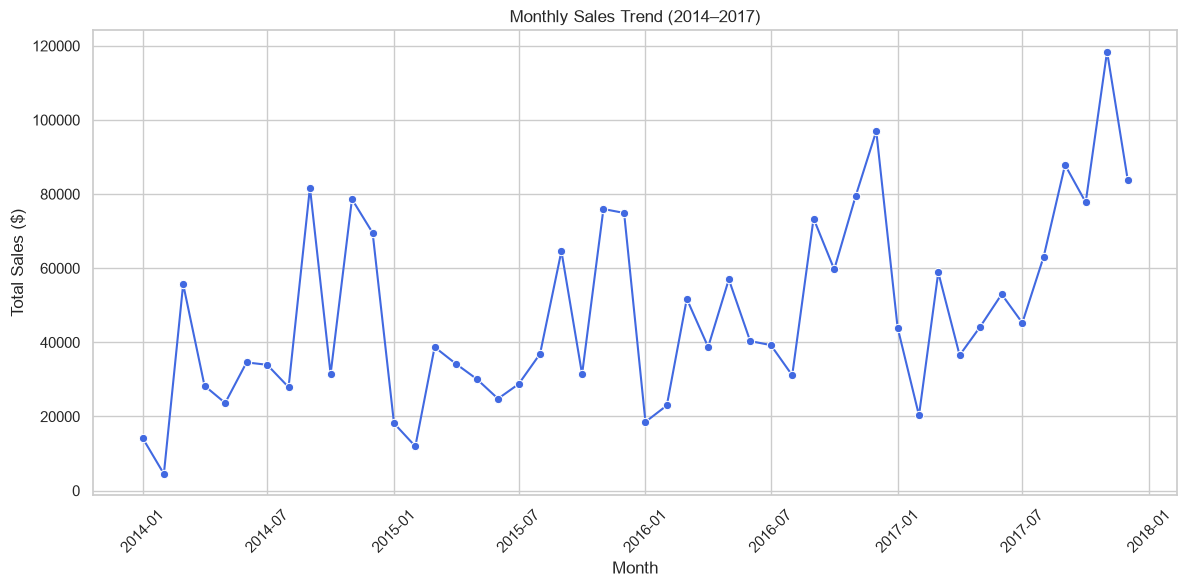

Monthly Sales Trend visualization saved successfully!


In [16]:
# Convert Order Date to datetime
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Check date conversion
print("Date column type:", df["Order Date"].dtype)
print("Invalid dates:", df["Order Date"].isna().sum())

# Calculate monthly sales
monthly_sales = (
    df.dropna(subset=["Order Date"])
      .set_index("Order Date")
      .resample("MS")["Sales"]
      .sum()
      .reset_index()
)

# Create visualization
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_sales,
    x="Order Date",
    y="Sales",
    marker="o",
    color="royalblue"
)

plt.title("Monthly Sales Trend (2014–2017)")
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=45)

plt.tight_layout()

# Save visualization
plt.savefig(
    "Visualizations/Monthly_Sales_Trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Monthly Sales Trend visualization saved successfully!")

#### Step 6.6: Subcategory profitability

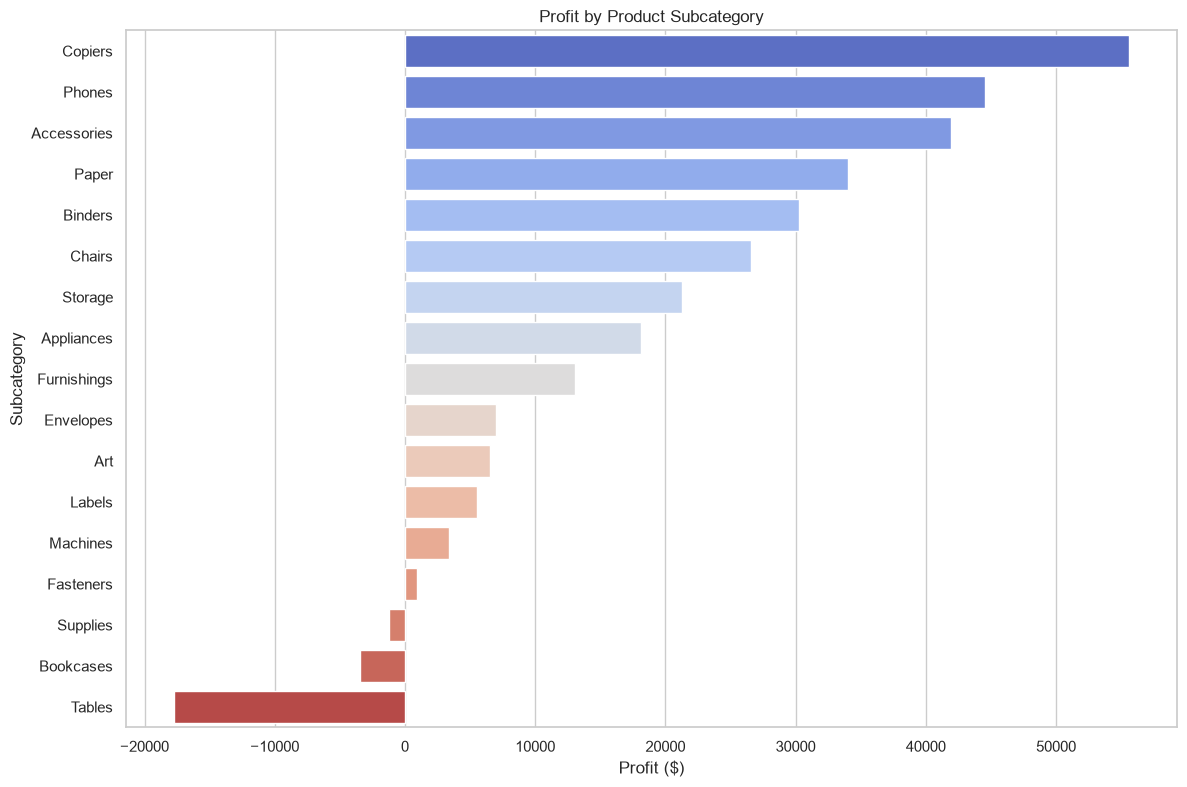

In [17]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=subcategory_analysis,
    x="Total_Profit",
    y="Sub-Category",
    hue="Sub-Category",
    palette="coolwarm",
    legend=False
)

plt.title("Profit by Product Subcategory")
plt.xlabel("Profit ($)")
plt.ylabel("Subcategory")
plt.tight_layout()
plt.savefig("Visualizations/Subcategory_Profit.png", dpi=300)
plt.show()

#### Step 6.7: Discount versus profit

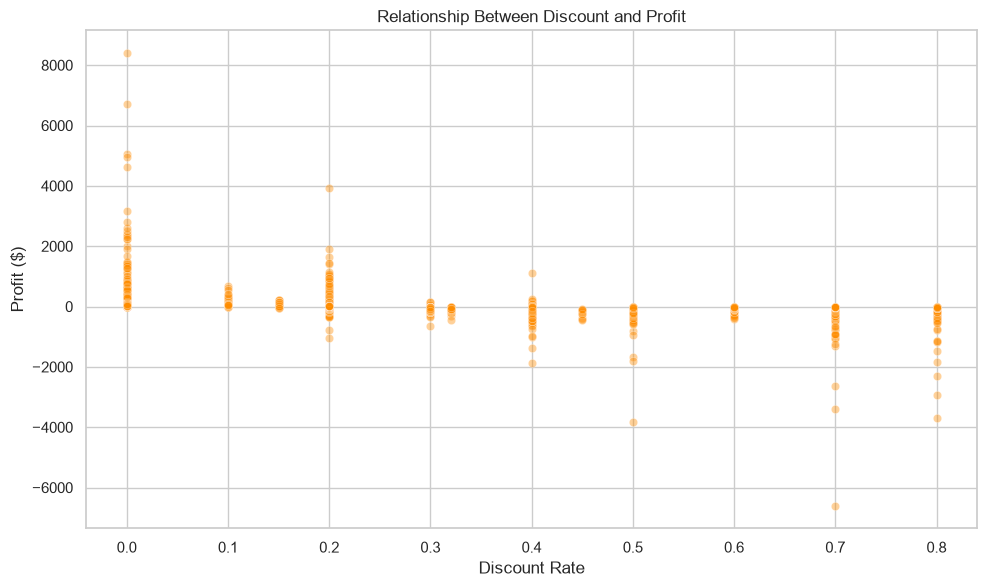

In [18]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    alpha=0.4,
    color="darkorange"
)

plt.title("Relationship Between Discount and Profit")
plt.xlabel("Discount Rate")
plt.ylabel("Profit ($)")
plt.tight_layout()
plt.savefig("Visualizations/Discount_vs_Profit.png", dpi=300)
plt.show()

#### Step 6.8: Sales distribution by shipping mode

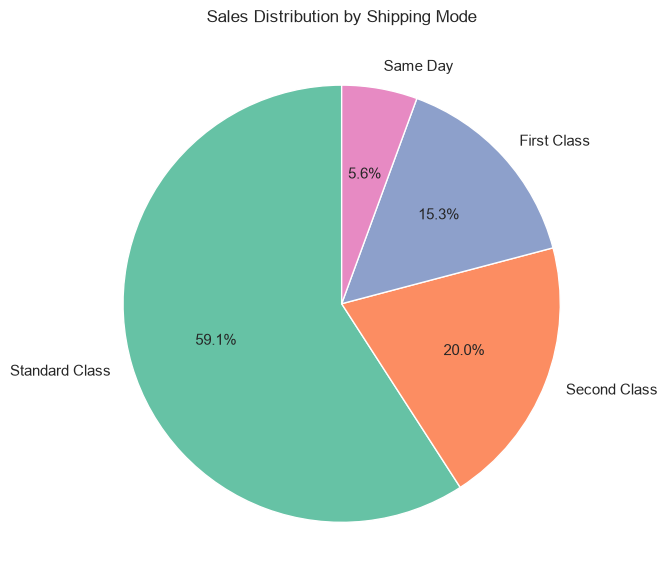

In [19]:
shipping_sales = (
    df.groupby("Ship Mode")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(9, 6))

plt.pie(
    shipping_sales,
    labels=shipping_sales.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Sales Distribution by Shipping Mode")
plt.tight_layout()
plt.savefig("Visualizations/Shipping_Mode_Sales.png", dpi=300)
plt.show()

#### Step 6.9: Regional profit margin

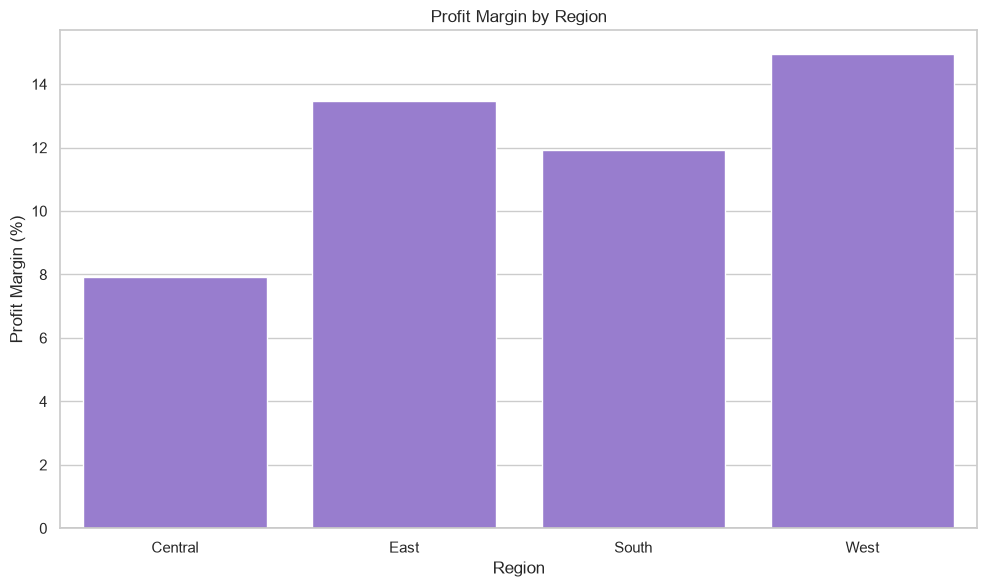

In [20]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=region_analysis,
    x="Region",
    y="Profit_Margin",
    color="mediumpurple"
)

plt.title("Profit Margin by Region")
plt.xlabel("Region")
plt.ylabel("Profit Margin (%)")
plt.axhline(0, color="black", linewidth=1)
plt.tight_layout()
plt.savefig("Visualizations/Regional_Profit_Margin.png", dpi=300)
plt.show()

### Step 7: Generating Business Insights

#### Step 7.1: Identifying and documenting business insights

INSIGHT 1

Technology is the most profitable category.

Technology generated $145,454.95 in profit, while Furniture generated only $18,451.27 despite substantial sales.



INSIGHT 2

The West region leads business performance.

The West generated $725,457.82 in sales and $108,418.45 in profit, with a 14.94% profit margin. Central had the lowest regional margin at 7.92%.



INSIGHT 3

The Consumer segment generates the most revenue.

Consumer customers contributed $1,161,401.34 in sales and $134,119.21 in profit.



INSIGHT 4

Tables are a major loss-making subcategory.

Tables generated a net loss of $17,725.48, followed by Bookcases and Supplies.



INSIGHT 5

High discounts are associated with losses.

Transactions with discounts of 30% or more show negative aggregate profit at each observed discount level. This indicates a need to review discount policies, although it does not establish causation.

#### Step 7.2: Generating an insights table using Python

In [21]:
business_insights = pd.DataFrame({
    "Business Area": [
        "Product Category",
        "Regional Performance",
        "Customer Segments",
        "Product Profitability",
        "Discount Strategy"
    ],
    "Key Finding": [
        "Technology generates the highest category profit.",
        "West has the highest sales and profit.",
        "Consumer segment contributes the most revenue.",
        "Tables generate substantial losses.",
        "Higher discounts are associated with negative profits."
    ],
    "Business Impact": [
        "Technology is an important profit contributor.",
        "West provides a benchmark for regional performance.",
        "Consumer retention can protect significant revenue.",
        "Loss-making products reduce overall profitability.",
        "Excessive discounting may weaken profit margins."
    ],
    "Recommendation": [
        "Prioritize profitable technology products.",
        "Investigate and improve Central region profitability.",
        "Develop targeted customer retention strategies.",
        "Review pricing and costs for Tables and Bookcases.",
        "Review discount levels and product-level profitability."
    ]
})

display(business_insights)

business_insights.to_csv(
    "Business_Insights.csv",
    index=False
)

print("Business insights saved successfully!")

,Business Area,Key Finding,Business Impact,Recommendation
0,Product Category,Technology generates the highest category profit.,Technology is an important profit contributor.,Prioritize profitable technology products.
1,Regional Performance,West has the highest sales and profit.,West provides a benchmark for regional perform...,Investigate and improve Central region profita...
2,Customer Segments,Consumer segment contributes the most revenue.,Consumer retention can protect significant rev...,Develop targeted customer retention strategies.
3,Product Profitability,Tables generate substantial losses.,Loss-making products reduce overall profitabil...,Review pricing and costs for Tables and Bookca...
4,Discount Strategy,Higher discounts are associated with negative ...,Excessive discounting may weaken profit margins.,Review discount levels and product-level profi...


Business insights saved successfully!


#### Step 7.3: Validating the discount insight

In [22]:
df["Discount_Group"] = pd.cut(
    df["Discount"],
    bins=[-0.01, 0.0, 0.2, 0.5, 1.0],
    labels=[
        "No Discount",
        "1–20%",
        "Above 20–50%",
        "Above 50%"
    ]
)

discount_analysis = df.groupby(
    "Discount_Group",
    observed=True
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Transactions=("Sales", "count")
).reset_index()

discount_analysis["Profit_Margin"] = (
    discount_analysis["Total_Profit"] /
    discount_analysis["Total_Sales"] * 100
)

display(discount_analysis.round(2))

discount_analysis.to_csv(
    "Discount_Analysis.csv",
    index=False
)

,Discount_Group,Total_Sales,Total_Profit,Transactions,Profit_Margin
0,No Discount,1087908.47,320987.60,4798,29.51
1,1–20%,846522.24,100785.47,3803,11.91
2,Above 20–50%,298541.41,-58817.00,537,-19.70
3,Above 50%,64228.74,-76559.05,856,-119.20


## Executive Summary

### Retail Sales Performance Analysis and Business Insights

**Business Objective:**  
The purpose of this analysis is to evaluate retail sales performance, identify profitable and underperforming business segments, examine the relationship between discounts and profitability, and recommend strategies to improve business performance.

**Dataset Overview:**  
The analysis uses the Sample Superstore dataset containing 9,994 transaction records across 21 attributes, covering the period from 2014 to 2017. Python, Pandas, NumPy, Matplotlib, and Seaborn were used for data exploration, KPI calculations, visualization, and analytical reporting.

**Key Performance Indicators:**

- Total Sales: $2,297,200.86
- Total Profit: $286,397.02
- Total Orders: 5,009
- Total Customers: 793
- Overall Profit Margin: 12.47%

**Major Findings:**

Technology emerged as the most profitable product category, generating approximately $145,455 in profit. The West region demonstrated strong performance, contributing approximately $725,458 in sales and $108,418 in profit. The Consumer segment accounted for the largest share of revenue.

However, profitability varied significantly across categories and regions. Furniture generated relatively low profit, with Tables contributing a net loss of approximately $17,725. Higher discount levels were also associated with weaker profitability, suggesting that existing pricing and promotional strategies require further evaluation.

**Business Implications:**

The findings indicate opportunities to strengthen overall profitability through improved product pricing, regional performance management, customer segmentation, and more selective discounting. Addressing loss-making products may improve financial performance without requiring equivalent increases in sales volume.

**Conclusion:**

The analysis demonstrates how business intelligence and data visualization can support evidence-based retail decisions. By prioritizing profitable products, investigating underperforming categories, and refining discount strategies, the organization can work toward sustainable revenue growth and improved profitability.

## Actionable Business Recommendations

Based on the analysis of the Superstore dataset, the following recommendations are proposed to improve business performance.

### 1. Optimize Product Pricing and Profitability

**Priority: High**

Review the pricing, procurement costs, and discount levels of loss-making subcategories, particularly Tables and Bookcases. Identify whether losses are concentrated in specific products, customer segments, or regions.

**Expected Impact:** Reduce avoidable losses and improve product-level profit margins.

### 2. Improve Discount Management

**Priority: High**

Introduce profitability-based discount guidelines and evaluate promotional campaigns according to their contribution to net profit rather than sales volume alone.

**Expected Impact:** Protect profit margins and reduce potentially unprofitable promotional activity.

### 3. Strengthen Regional Performance

**Priority: High**

Investigate factors contributing to the Central region's comparatively low profit margin. Compare product mix, discounting practices, and customer demand with better-performing regions.

**Expected Impact:** Identify operational and pricing opportunities that may improve regional profitability.

### 4. Prioritize Profitable Product Categories

**Priority: Medium**

Review opportunities to expand profitable Technology product lines while maintaining appropriate inventory levels and monitoring customer demand.

**Expected Impact:** Improve the contribution of profitable products to overall business performance.

### 5. Improve Customer Segmentation Strategies

**Priority: Medium**

Develop targeted marketing and retention initiatives for Consumer, Corporate, and Home Office customers based on purchasing behavior, order value, and profitability.

**Expected Impact:** Improve customer engagement, retention, and revenue quality.

### 6. Establish Continuous Performance Monitoring

**Priority: Medium**

Implement a monthly analytics dashboard that tracks total sales, profit, profit margin, regional performance, category performance, and discount-related losses.

**Expected Impact:** Enable earlier identification of performance problems and support timely business decisions.

## Suggested Implementation Timeline

| Timeline | Recommended Action |
|---|---|
| First 30 days | Review loss-making products and discount practices |
| Days 31–60 | Investigate regional performance and test pricing improvements |
| Days 61–90 | Evaluate results and expand effective strategies |
| Ongoing | Monitor KPIs through monthly business reports |

## Final Recommendation

The organization should initially prioritize profitability improvement rather than revenue growth alone. Product-level loss reduction and discount optimization are the most immediate areas for investigation. All proposed changes should be evaluated through measurable KPIs before wider implementation.

### Saving final analytical findings

In [23]:
recommendations = pd.DataFrame({
    "Priority": ["High", "High", "High", "Medium", "Medium", "Medium"],
    "Business Area": [
        "Product Pricing",
        "Discount Management",
        "Regional Performance",
        "Product Strategy",
        "Customer Segmentation",
        "Performance Monitoring"
    ],
    "Recommended Action": [
        "Review loss-making products and pricing.",
        "Establish profitability-based discount guidelines.",
        "Investigate Central region's low margins.",
        "Evaluate expansion of profitable Technology products.",
        "Develop targeted customer strategies.",
        "Create a monthly KPI monitoring dashboard."
    ]
})

with pd.ExcelWriter("Retail_Business_Analytics.xlsx") as writer:
    kpi_summary.to_excel(writer, sheet_name="KPIs", index=False)
    category_analysis.to_excel(writer, sheet_name="Categories", index=False)
    region_analysis.to_excel(writer, sheet_name="Regions", index=False)
    segment_analysis.to_excel(writer, sheet_name="Segments", index=False)
    subcategory_analysis.to_excel(writer, sheet_name="Subcategories", index=False)
    discount_analysis.to_excel(writer, sheet_name="Discount Analysis", index=False)
    business_insights.to_excel(writer, sheet_name="Insights", index=False)
    recommendations.to_excel(writer, sheet_name="Recommendations", index=False)

print("Business analytics workbook created successfully!")

Business analytics workbook created successfully!
